# Early experimental draft: exploration, features, and prototype modeling

\<write here on the initial question, exploratory workflow before code implementation, and how this draft led to the reusable pipeline>

## 1. Setup and source data

\<write here on data sources, target classes, identifiers, and the unit of observation>

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.neighbors import BallTree, KNeighborsClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, LabelEncoder
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
labels = pd.read_csv(ROOT / "0bf8bc6e-30d0-4c50-956a-603fc693d966.csv")
data = pd.read_csv(ROOT / "4910797b-ee55-40a7-8668-10efd5c1b960.csv")
display(data.head())
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 59400 entries, 0 to 59399
Data columns (total 40 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   id                     59400 non-null  int64  
 1   amount_tsh             59400 non-null  float64
 2   date_recorded          59400 non-null  str    
 3   funder                 55763 non-null  str    
 4   gps_height             59400 non-null  int64  
 5   installer              55745 non-null  str    
 6   longitude              59400 non-null  float64
 7   latitude               59400 non-null  float64
 8   wpt_name               59398 non-null  str    
 9   num_private            59400 non-null  int64  
 10  basin                  59400 non-null  str    
 11  subvillage             59029 non-null  str    
 12  region                 59400 non-null  str    
 13  region_code            59400 non-null  int64  
 14  district_code          59400 non-null  int64  
 15  lga          

,id,amount_tsh,date_recorded,funder,gps_height,installer,longitude,latitude,wpt_name,num_private,basin,subvillage,region,region_code,district_code,lga,ward,population,public_meeting,recorded_by,scheme_management,scheme_name,permit,construction_year,extraction_type,extraction_type_group,extraction_type_class,management,management_group,payment,payment_type,water_quality,quality_group,quantity,quantity_group,source,source_type,source_class,waterpoint_type,waterpoint_type_group
0,69572,6000.0,2011-03-14,Roman,1390,Roman,34.938093,-9.856322,none,0,Lake Nyasa,Mnyusi B,Iringa,11,5,Ludewa,Mundindi,109,True,GeoData Consultants Ltd,VWC,Roman,False,1999,gravity,gravity,gravity,vwc,user-group,pay annually,annually,soft,good,enough,enough,spring,spring,groundwater,communal standpipe,communal standpipe
1,8776,0.0,2013-03-06,Grumeti,1399,GRUMETI,34.698766,-2.147466,Zahanati,0,Lake Victoria,Nyamara,Mara,20,2,Serengeti,Natta,280,NaN,GeoData Consultants Ltd,Other,NaN,True,2010,gravity,gravity,gravity,wug,user-group,never pay,never pay,soft,good,insufficient,insufficient,rainwater harvesting,rainwater harvesting,surface,communal standpipe,communal standpipe
2,34310,25.0,2013-02-25,Lottery Club,686,World vision,37.460664,-3.821329,Kwa Mahundi,0,Pangani,Majengo,Manyara,21,4,Simanjiro,Ngorika,250,True,GeoData Consultants Ltd,VWC,Nyumba ya mungu pipe scheme,True,2009,gravity,gravity,gravity,vwc,user-group,pay per bucket,per bucket,soft,good,enough,enough,dam,dam,surface,communal standpipe multiple,communal standpipe
3,67743,0.0,2013-01-28,Unicef,263,UNICEF,38.486161,-11.155298,Zahanati Ya Nanyumbu,0,Ruvuma / Southern Coast,Mahakamani,Mtwara,90,63,Nanyumbu,Nanyumbu,58,True,GeoData Consultants Ltd,VWC,NaN,True,1986,submersible,submersible,submersible,vwc,user-group,never pay,never pay,soft,good,dry,dry,machine dbh,borehole,groundwater,communal standpipe multiple,communal standpipe
4,19728,0.0,2011-07-13,Action In A,0,Artisan,31.130847,-1.825359,Shuleni,0,Lake Victoria,Kyanyamisa,Kagera,18,1,Karagwe,Nyakasimbi,0,True,GeoData Consultants Ltd,NaN,NaN,True,0,gravity,gravity,gravity,other,other,never pay,never pay,soft,good,seasonal,seasonal,rainwater harvesting,rainwater harvesting,surface,communal standpipe,communal standpipe


In [2]:
display(pd.Series({"rows": len(data), "unique_wells": data["id"].nunique(),
                   "max_rows_per_id": data["id"].value_counts().max()}))
data = data.merge(labels, on="id", how="left", validate="many_to_one")
display(data["status_group"].value_counts())
display(data.isna().sum().loc[lambda counts: counts.gt(0)].sort_values(ascending=False))

rows               59400
unique_wells       59400
max_rows_per_id        1
dtype: int64

status_group
functional                 32259
non functional             22824
functional needs repair     4317
Name: count, dtype: int64

scheme_name          28810
scheme_management     3878
installer             3655
funder                3637
public_meeting        3334
permit                3056
subvillage             371
wpt_name                 2
dtype: int64

## 2. Feature overlap and category distributions

\<write here on duplicated category groupings, cardinality, and candidate feature exclusions>

In [3]:
display(data.loc[data["quantity"].ne(data["quantity_group"]), ["quantity", "quantity_group"]].head())
waterpoint_differences = data.loc[data["waterpoint_type"].ne(data["waterpoint_type_group"])]
display(waterpoint_differences["waterpoint_type"].value_counts())
display(waterpoint_differences["waterpoint_type_group"].value_counts())
display(data.nunique().sort_values(ascending=False))
display(data["water_quality"].value_counts())

,quantity,quantity_group


waterpoint_type
communal standpipe multiple    6103
Name: count, dtype: int64

waterpoint_type_group
communal standpipe    6103
Name: count, dtype: int64

id                       59400
latitude                 57517
longitude                57516
wpt_name                 37399
subvillage               19287
scheme_name               2695
gps_height                2428
installer                 2145
ward                      2092
funder                    1896
population                1049
date_recorded              356
lga                        125
amount_tsh                  98
num_private                 65
construction_year           55
region_code                 27
region                      21
district_code               20
extraction_type             18
extraction_type_group       13
management                  12
scheme_management           11
source                      10
basin                        9
water_quality                8
extraction_type_class        7
payment                      7
payment_type                 7
waterpoint_type              7
source_type                  7
quality_group                6
waterpoi

water_quality
soft                  50818
salty                  4856
unknown                1876
milky                   804
coloured                490
salty abandoned         339
fluoride                200
fluoride abandoned       17
Name: count, dtype: int64

## 3. Exploratory spatial features: nearby well counts

\<write here on BallTree distances, the four radii, self-exclusion, and the full-data reference used in this early draft>

In [4]:
import numpy as np
from sklearn.neighbors import BallTree

def count_nearby_wells(df, radius_km=20):
    # BallTree expects [latitude, longitude] in radians
    coords = np.radians(df[['latitude', 'longitude']].to_numpy())

    tree = BallTree(coords, metric='haversine')

    # Convert kilometers to radians
    radius_rad = radius_km / 6371.0

    # Count wells within radius
    counts = tree.query_radius(coords, r=radius_rad, count_only=True)

    # Subtract 1 to exclude the well itself
    return counts - 1

for km in [3,5,10,20]:
    label = f'nearby_wells_{str(km)}km'

    data[label] = np.nan

    valid = data[['latitude', 'longitude']].notna().all(axis=1)

    data.loc[valid, label] = count_nearby_wells(
        data.loc[valid],
        radius_km=km
    )

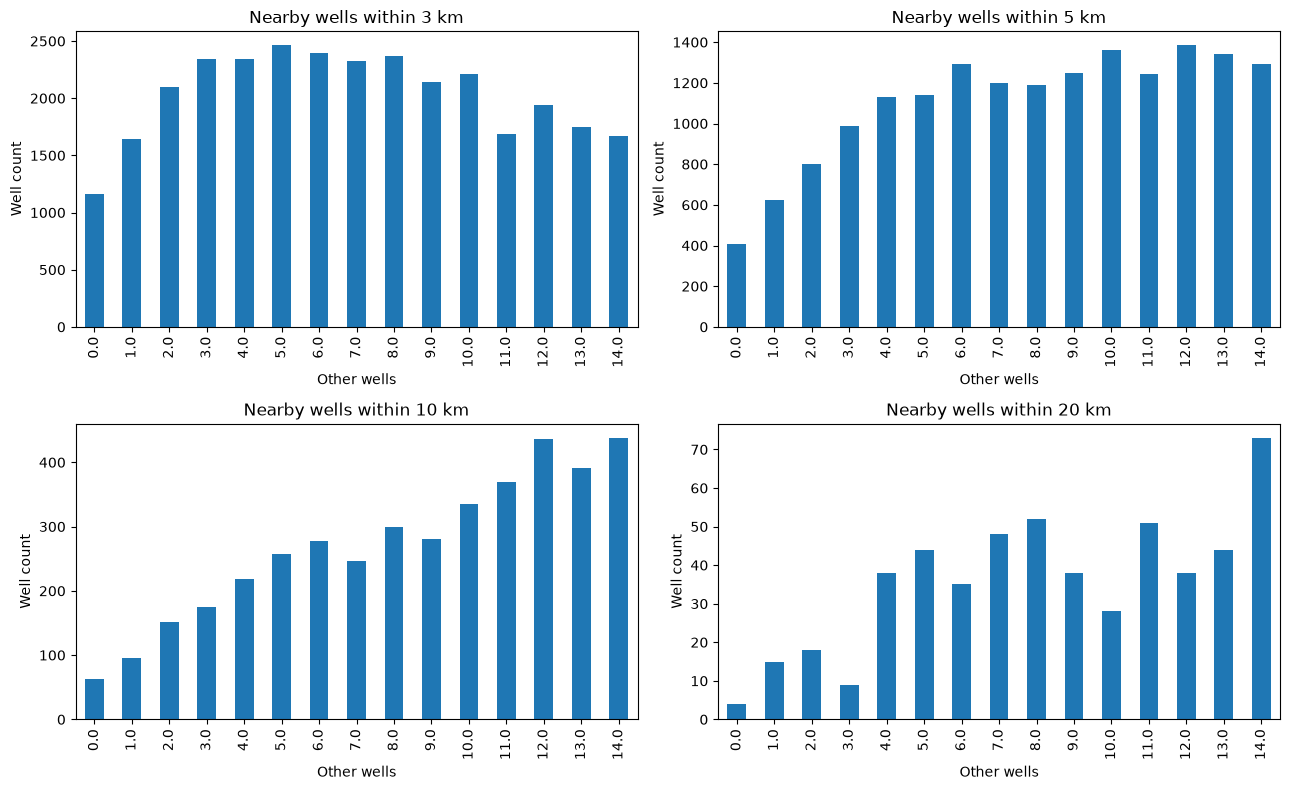

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for radius, ax in zip([3, 5, 10, 20], axes.flat):
    column = f"nearby_wells_{radius}km"
    data[column].value_counts().sort_index().head(15).plot.bar(ax=ax)
    ax.set(title=f"Nearby wells within {radius} km", xlabel="Other wells", ylabel="Well count")
fig.tight_layout()
plt.show()

## 4. Well age and unknown construction years

\<write here on recording dates, zero construction years, negative ages, and missingness indicators>

In [6]:
data["date_recorded"] = pd.to_datetime(data["date_recorded"])

data["well_age"] = (
    data["date_recorded"].dt.year
    - data["construction_year"]
)

data.loc[
    (data["construction_year"] == 0) |
    (data["well_age"] < 0),
    "well_age"
] = np.nan

In [7]:
data["construction_year_missing"] = data["construction_year"].eq(0).astype(int)
data["construction_year"] = data["construction_year"].replace(0, np.nan)
data["wpt_name"] = data["wpt_name"].fillna("none")
display(data[["well_age", "construction_year", "construction_year_missing"]].describe())

,well_age,construction_year,construction_year_missing
count,38682.000000,38691.000000,59400.000000
mean,15.360245,1996.814686,0.348636
std,12.490610,12.472045,0.476543
min,0.000000,1960.000000,0.000000
25%,5.000000,1987.000000,0.000000
50%,13.000000,2000.000000,0.000000
75%,25.000000,2008.000000,1.000000
max,53.000000,2013.000000,1.000000


## 5. Missing-value experiments

\<write here on why rows are retained, existing Unknown categories, and missingness by field>

In [8]:
display(data.isna().sum().loc[lambda counts: counts.gt(0)])
for column in ["funder", "installer", "scheme_management", "scheme_name", "permit", "public_meeting"]:
    display(data[column].value_counts(dropna=False).head(15).rename(column))

funder                3637
installer             3655
subvillage             371
public_meeting        3334
scheme_management     3878
scheme_name          28810
permit                3056
construction_year    20709
well_age             20718
dtype: int64

funder
Government Of Tanzania    9084
NaN                       3637
Danida                    3114
Hesawa                    2202
Rwssp                     1374
World Bank                1349
Kkkt                      1287
World Vision              1246
Unicef                    1057
Tasaf                      877
District Council           843
Dhv                        829
Private Individual         826
Dwsp                       811
0                          777
Name: funder, dtype: int64

installer
DWE                   17402
NaN                    3655
Government             1825
RWE                    1206
Commu                  1060
DANIDA                 1050
KKKT                    898
Hesawa                  840
0                       777
TCRS                    707
Central government      622
CES                     610
Community               553
DANID                   552
District Council        551
Name: installer, dtype: int64

scheme_management
VWC                 36793
WUG                  5206
NaN                  3878
Water authority      3153
WUA                  2883
Water Board          2748
Parastatal           1680
Private operator     1063
Company              1061
Other                 766
SWC                    97
Trust                  72
Name: scheme_management, dtype: int64

scheme_name
NaN                                      28810
K                                          682
Borehole                                   546
Chalinze wate                              405
M                                          400
DANIDA                                     379
Government                                 320
Ngana water supplied scheme                270
wanging'ombe water supply s                261
wanging'ombe supply scheme                 234
Bagamoyo wate                              229
I                                          229
Uroki-Bomang'ombe water sup                209
N                                          204
Kirua kahe gravity water supply trust      193
Name: scheme_name, dtype: int64

permit
True     38852
False    17492
NaN       3056
Name: permit, dtype: int64

public_meeting
True     51011
False     5055
NaN       3334
Name: public_meeting, dtype: int64

### 5.1. Subvillage inference from geographic neighbors

\<write here on the geographic imputation hypothesis, coordinate exclusions, validation accuracy, and why subvillage was excluded later>

In [9]:
geo_cols = [
    'longitude', 'latitude', 'gps_height',
    'basin', 'subvillage', 'region', 'region_code',
    'district_code', 'lga', 'ward', 'population'
]

print(data[data['subvillage'].isna()][geo_cols].head(3).T)

                       342           360          379
longitude        36.557631     36.416701    36.729383
latitude         -6.233394     -6.220157    -6.084255
gps_height               0             0            0
basin          Wami / Ruvu   Wami / Ruvu  Wami / Ruvu
subvillage             NaN           NaN          NaN
region              Dodoma        Dodoma       Dodoma
region_code              1             1            1
district_code            3             3            3
lga                 Kongwa        Kongwa       Kongwa
ward                Sagara  Kongwa Urban   Pandambili
population               0             0            0


In [10]:
print((data[data['subvillage'].isna()][geo_cols]['population'] != 0).sum())

10


In [11]:
import numpy as np
import pandas as pd
from sklearn.neighbors import KNeighborsClassifier

def impute_subvillage(df, k=5):
    df = df.copy()

    coords = ['latitude', 'longitude']

    known = df[
        df['subvillage'].notna()
        & df[coords].notna().all(axis=1)
        & df['latitude'].between(-90, 90)
        & df['longitude'].between(-180, 180)
        & df['longitude'].ne(0)
    ]

    missing = df[
        df['subvillage'].isna()
        & df[coords].notna().all(axis=1)
        & df['latitude'].between(-90, 90)
        & df['longitude'].between(-180, 180)
        & df['longitude'].ne(0)
    ]

    if known.empty or missing.empty:
        return df

    model = KNeighborsClassifier(
        n_neighbors=min(k, len(known)),
        weights='distance',
        metric='haversine',
        algorithm='ball_tree'
    )

    model.fit(
        np.radians(known[coords]),
        known['subvillage']
    )

    df.loc[missing.index, 'subvillage'] = model.predict(
        np.radians(missing[coords])
    )

    return df

In [12]:
data_with_inferred_subvillages = impute_subvillage(data, k=5)
pd.Series({"missing_before": data["subvillage"].isna().sum(),
           "missing_after": data_with_inferred_subvillages["subvillage"].isna().sum()})

missing_before    371
missing_after       0
dtype: int64

In [13]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

def evaluate_subvillage_imputation(df, k=5, test_size=0.2):
    coords = ['latitude', 'longitude']

    valid = df[
        df['subvillage'].notna()
        & df[coords].notna().all(axis=1)
        & df['latitude'].between(-90, 90)
        & df['longitude'].between(-180, 180)
        & df['longitude'].ne(0)
    ]

    train, test = train_test_split(
        valid,
        test_size=test_size,
        random_state=42
    )

    model = KNeighborsClassifier(
        n_neighbors=min(k, len(train)),
        weights='distance',
        metric='haversine',
        algorithm='ball_tree'
    )

    model.fit(
        np.radians(train[coords]),
        train['subvillage']
    )

    predictions = model.predict(
        np.radians(test[coords])
    )

    accuracy = accuracy_score(
        test['subvillage'],
        predictions
    )

    print(f"Accuracy: {accuracy:.2%}")
    print(f"Correct: {(predictions == test['subvillage']).sum()}/{len(test)}")

    return accuracy

In [14]:
subvillage_imputation_accuracy = evaluate_subvillage_imputation(data, k=5)

Accuracy: 51.07%
Correct: 5845/11444


### 5.2. Constant filling for categorical fields

\<write here on Unknown as the shared missing category and consistent string encoding for mixed boolean fields>

In [15]:
impute_columns = ["funder", "installer", "public_meeting", "scheme_management", "scheme_name", "permit"]
for column in impute_columns:
    filled = data[column].astype(object).fillna("Unknown")
    display(filled.value_counts(dropna=False).head(10).rename(column))

funder
Government Of Tanzania    9084
Unknown                   3641
Danida                    3114
Hesawa                    2202
Rwssp                     1374
World Bank                1349
Kkkt                      1287
World Vision              1246
Unicef                    1057
Tasaf                      877
Name: funder, dtype: int64

installer
DWE           17402
Unknown        3658
Government     1825
RWE            1206
Commu          1060
DANIDA         1050
KKKT            898
Hesawa          840
0               777
TCRS            707
Name: installer, dtype: int64

public_meeting
True       51011
False       5055
Unknown     3334
Name: public_meeting, dtype: int64

scheme_management
VWC                 36793
WUG                  5206
Unknown              3878
Water authority      3153
WUA                  2883
Water Board          2748
Parastatal           1680
Private operator     1063
Company              1061
Other                 766
Name: scheme_management, dtype: int64

scheme_name
Unknown                        28810
K                                682
Borehole                         546
Chalinze wate                    405
M                                400
DANIDA                           379
Government                       320
Ngana water supplied scheme      270
wanging'ombe water supply s      261
wanging'ombe supply scheme       234
Name: scheme_name, dtype: int64

permit
True       38852
False      17492
Unknown     3056
Name: permit, dtype: int64

## 6. Categorical cardinality and prototype encoding

\<write here on rare categories, sparse one-hot encoding, identifier treatment, and dropping subvillage and recording date>

In [16]:
data = data.sort_values("date_recorded").reset_index(drop=True)
data = data.drop(columns=["date_recorded", "subvillage"])
display(data.select_dtypes(include=["object", "string"]).nunique().sort_values(ascending=False))
display(data.select_dtypes(include=["object", "string"]).apply(
    lambda column: pd.Series({"most_frequent": column.value_counts().max(),
                              "median_frequency": column.value_counts().median(),
                              "p90_frequency": column.value_counts().quantile(0.9)})
).T)

wpt_name                 37399
scheme_name               2695
installer                 2145
ward                      2092
funder                    1896
lga                        125
region                      21
extraction_type             18
extraction_type_group       13
management                  12
scheme_management           11
source                      10
basin                        9
water_quality                8
payment_type                 7
waterpoint_type              7
source_type                  7
extraction_type_class        7
payment                      7
quality_group                6
waterpoint_type_group        6
management_group             5
quantity                     5
quantity_group               5
source_class                 3
status_group                 3
permit                       2
public_meeting               2
recorded_by                  1
dtype: int64

,most_frequent,median_frequency,p90_frequency
funder,9084.0,1.0,32.0
installer,17402.0,1.0,25.6
wpt_name,3565.0,1.0,2.0
basin,10248.0,6432.0,9201.6
region,5294.0,2635.0,4639.0
lga,2503.0,399.0,875.8
ward,307.0,20.0,60.0
public_meeting,51011.0,28033.0,46415.4
recorded_by,59400.0,59400.0,59400.0
scheme_management,36793.0,1680.0,5206.0


In [17]:
def make_encoder():
    return OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=20,
                         max_categories=50, sparse_output=True)

def fill_unknown(frame):
    return frame.astype(object).fillna("Unknown")

def fill_unknown_strings(frame):
    return fill_unknown(frame).astype(str)

data_x = data.drop(columns="status_group")
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(data["status_group"])
other_cat_columns = data_x.select_dtypes(include=["object", "category", "bool", "string"]).columns.difference(impute_columns).tolist()
number_columns = data_x.select_dtypes(include="number").columns.tolist()
transformers = []
for column in impute_columns:
    fill = fill_unknown_strings if column in ["public_meeting", "permit"] else fill_unknown
    transformers.append((column, Pipeline([
        ("impute", FunctionTransformer(fill, feature_names_out="one-to-one")),
        ("encode", make_encoder()),
    ]), [column]))
transformers.extend([
    ("other_categorical", make_encoder(), other_cat_columns),
    ("numerical", "passthrough", number_columns),
])
col_transformer = ColumnTransformer(transformers, remainder="drop")
X_transformed = col_transformer.fit_transform(data_x)
feature_names = col_transformer.get_feature_names_out()
display(pd.Series({"raw_columns": data_x.shape[1], "encoded_columns": X_transformed.shape[1]}))
display(pd.DataFrame({"feature_name": feature_names}))

raw_columns         44
encoded_columns    491
dtype: int64

,feature_name
0,funder__funder_0
1,funder__funder_Adb
2,funder__funder_Adra
3,funder__funder_Amref
4,funder__funder_Ces(gmbh)
...,...
486,numerical__nearby_wells_5km
487,numerical__nearby_wells_10km
488,numerical__nearby_wells_20km
489,numerical__well_age


In [18]:
for name, transformer, columns in col_transformer.transformers_:

    if isinstance(transformer, Pipeline):
        encoder = transformer.named_steps["encode"]

    elif isinstance(transformer, OneHotEncoder):
        encoder = transformer

    else:
        continue

    print(f"\n--- {name} ---")

    for col, infrequent in zip(
        columns,
        encoder.infrequent_categories_
    ):
        if infrequent is not None:
            print(f"{col}: {len(infrequent)} categories grouped")


--- funder ---
funder: 1847 categories grouped

--- installer ---
installer: 2096 categories grouped

--- public_meeting ---

--- scheme_management ---

--- scheme_name ---
scheme_name: 2647 categories grouped

--- permit ---

--- other_categorical ---
extraction_type: 1 categories grouped
lga: 76 categories grouped
ward: 2043 categories grouped
water_quality: 1 categories grouped
waterpoint_type: 1 categories grouped
waterpoint_type_group: 1 categories grouped
wpt_name: 37350 categories grouped


## 7. Historical prototype: training and evaluation

\<write here on XGBoost configuration, the random split, preprocessing fitted before the split, full-data neighbor features, and limitations corrected by the implemented pipeline>

In [19]:
from sklearn.model_selection import train_test_split
from xgboost import XGBClassifier

X_train, X_test, y_train, y_test = train_test_split(X_transformed, y, test_size=0.25, shuffle=True, random_state=42)

model = XGBClassifier(
    objective="multi:softprob",
    num_class=3,
    n_estimators=500,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=1.0,
    eval_metric="mlogloss",
    random_state=42,
    n_jobs=-1
)
model = model.fit(X_train, y_train)

In [20]:
from sklearn.metrics import classification_report, confusion_matrix
import pandas as pd

y_pred = model.predict(X_test)

print(classification_report(
    y_test,
    y_pred,
    target_names=label_encoder.classes_
))

cm = confusion_matrix(y_test, y_pred)

display(pd.DataFrame(
    cm,
    index=label_encoder.classes_,
    columns=label_encoder.classes_
))

                         precision    recall  f1-score   support

             functional       0.76      0.93      0.83      8026
functional needs repair       0.75      0.23      0.35      1103
         non functional       0.85      0.70      0.77      5721

               accuracy                           0.79     14850
              macro avg       0.79      0.62      0.65     14850
           weighted avg       0.79      0.79      0.77     14850



,functional,functional needs repair,non functional
functional,7427,55,544
functional needs repair,686,254,163
non functional,1675,29,4017


### 7.1. Feature importance

\<write here on dominant features, the role of identifiers and geography, and ideas for subsequent experiments>

,feature,importance
302,other_categorical__quantity_dry,0.042466
228,other_categorical__lga_Kigoma Rural,0.042134
423,other_categorical__waterpoint_type_group_other,0.039393
307,other_categorical__quantity_group_dry,0.033914
417,other_categorical__waterpoint_type_other,0.028154
...,...,...
151,scheme_name__scheme_name_Roman,0.000000
466,other_categorical__wpt_name_Tank La Shule,0.000000
467,other_categorical__wpt_name_Tankini,0.000000
376,other_categorical__ward_Maposeni,0.000000


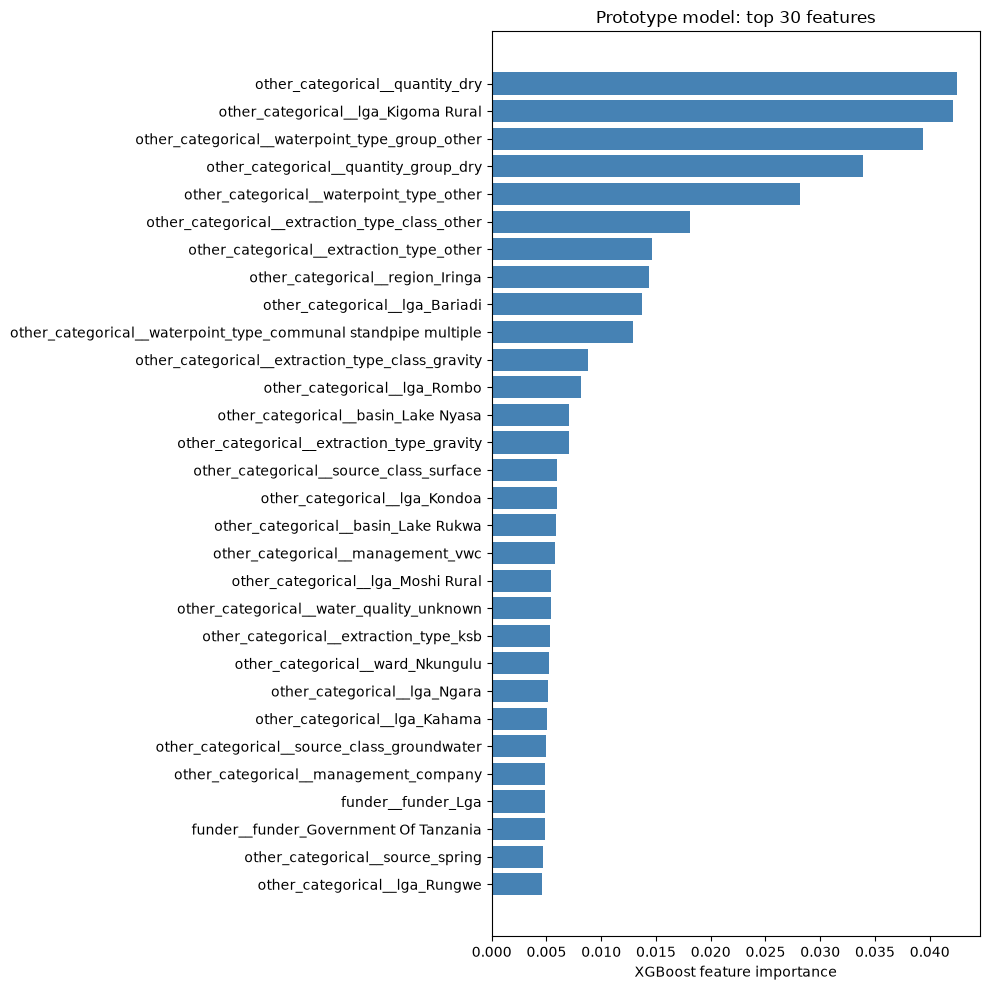

In [21]:
importance_df = pd.DataFrame({"feature": feature_names, "importance": model.feature_importances_}).sort_values("importance", ascending=False)
display(importance_df)
top_features = importance_df.head(30).iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 10))
ax.barh(top_features["feature"], top_features["importance"], color="steelblue")
ax.set(title="Prototype model: top 30 features", xlabel="XGBoost feature importance")
fig.tight_layout()
plt.show()

## 8. Population-data limitations and the next experiments

\<write here on zero population values, population by well status, external raster enrichment, and the transition to geographic access KPIs>

zero_population_wells    21381.000000
share_zero_population        0.359949
dtype: float64

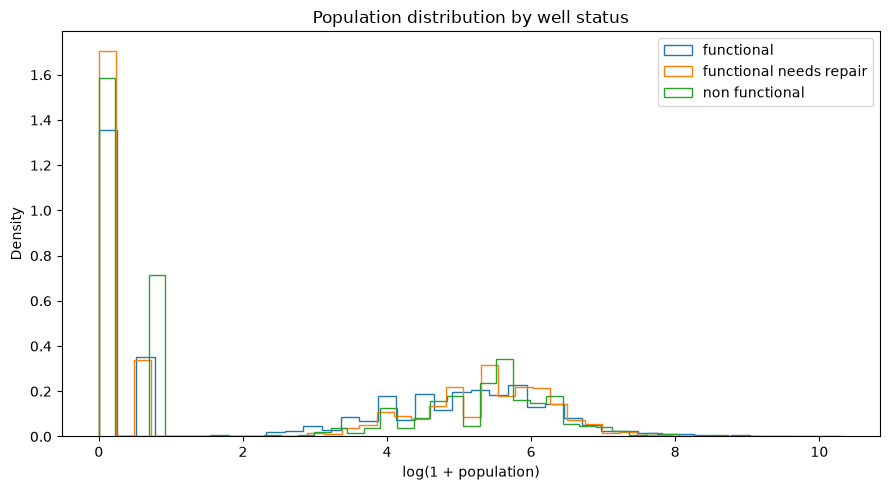

In [22]:
display(pd.Series({"zero_population_wells": data["population"].eq(0).sum(),
                   "share_zero_population": data["population"].eq(0).mean()}))
fig, ax = plt.subplots(figsize=(9, 5))
for status, group in data.groupby("status_group"):
    ax.hist(np.log1p(group["population"].dropna()), bins=40, density=True,
            histtype="step", label=status)
ax.set(title="Population distribution by well status", xlabel="log(1 + population)", ylabel="Density")
ax.legend()
fig.tight_layout()
plt.show()